# Studying biomass function and mutant relation

In [7]:
import reframed
import pandas as pd
import matplotlib.pyplot as plt

import json
import sys
import seaborn as sns

In [ ]:
import molmass

sys.path.append("../scripts_python/")
import prepare_files_for_simulation
import Guillen2021.prepare_models_guillen2021 as prepare_models_guillen2021

sys.path.append("../functions/")
import simulation.general as general
from simulation.minimal_medium import make_minimal_media_df

In [9]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
models_ecoli = general.load_models_guillen2021(all_38_strains=False)

INFO     | Loading models for Guillen et al (2021)...


In [ ]:
model_ecoli = general.load_ecoli_model()
models_wt = {"wild_type": model_ecoli}

In [ ]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
m9_compounds = media_db.query("medium == 'M9'").compound.values
env_m9 = reframed.Environment.from_compounds(m9_compounds)

lb_compounds = media_db.query("medium == 'LB'").compound.values
env_lb = reframed.Environment.from_compounds(lb_compounds)

In [ ]:
mutant_types_df = pd.read_excel("../data/Guillen2021/mmc3.xlsx",sheet_name="annotated")
mutant_types_df.ID = mutant_types_df.ID.map(lambda x:"mutant_"+x)
mutant_types_df.rename(columns={"ID":"member"},inplace=True)

### Minimal medium for wild type and mutants

In [9]:
minimal_media_df_ecoli = pd.read_csv("../output/Guillen2021/minimal_media.tsv",sep="\t",index_col=0)

# find the minimal medium for the wild type (for comparison)
minimal_media_df_ecoli_wt = make_minimal_media_df(models_wt,
                                               env_lb,
                                               min_growth=0.1,
                                               n_solutions=100,
                                               max_uptake=1)

# combine with mutants
minimal_medium_all = pd.concat([minimal_media_df_ecoli,minimal_media_df_ecoli_wt],axis=1).fillna(0)

# remove all compounds of m9 medium
m9_rxns = [f"R_EX_{met}_e" for met in m9_compounds]
minimal_medium_all = minimal_medium_all[~minimal_medium_all.index.isin(m9_rxns)]


Started analysis for wild_type
iML1515: Objective: 2151.3262
Status: Optimal



/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/minimal_medium.py:265: UserWarning: Solution appears to be invalid.
  warn('Solution appears to be invalid.')


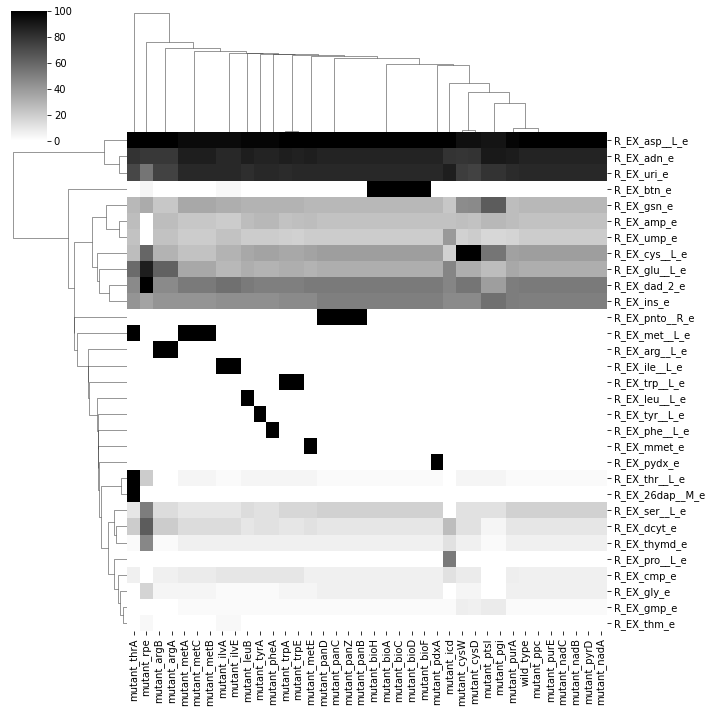

In [10]:
g = sns.clustermap(minimal_medium_all,cmap="binary",vmin=0)

In [11]:
# Find mutants with the same solution for the minimal medium as the wild type
same_mm_wild_type = minimal_medium_all.columns[minimal_medium_all.eq(minimal_medium_all['wild_type'], axis=0).all()].to_list()
relevant_mutants = set(still_growing+same_mm_wild_type)-{"wild_type"}
relevant_mutants


{'mutant_nadA',
 'mutant_nadB',
 'mutant_nadC',
 'mutant_pgi',
 'mutant_ppc',
 'mutant_ptsI',
 'mutant_purE',
 'mutant_pyrD',
 'mutant_rpe'}

### Look at genes for strange behaving mutants

In [12]:
# Load relevant data
geneid2name = pd.read_csv("../data/Guillen2021/generated/gene_id2name.tsv", sep="\t", index_col=0)["name"].to_dict() # For whole E.coli model

#From mutants get the gene ids
genes_names = [mut.split("_")[-1] for mut in relevant_mutants] 
name2gene_id = {name: gene_id for gene_id, name in geneid2name.items()}
genes_ids = [name2gene_id[name] for name in genes_names if name in name2gene_id]


In [13]:
genes_ids

['G_b0750',
 'G_b3956',
 'G_b2574',
 'G_b0109',
 'G_b3386',
 'G_b4025',
 'G_b0945',
 'G_b2416',
 'G_b0523']

In [14]:
complete_env = reframed.Environment.complete(model_ecoli)
complete_env.apply(model_ecoli,inplace=True)

convert2df = lambda fva_results: pd.DataFrame.from_dict(fva_results, orient='index',columns=["lb","ub"])

list_combined = []
# Find effect of gene deletion
for gene_name in genes_names:
    # Gather data
    gene_id = name2gene_id[gene_name]
    targeted_rxns = model_ecoli.gene_to_reaction_lookup()[gene_id]
    model_copy = models_ecoli[f"mutant_{gene_name}"].copy()

    # Apply complete media
    complete_env.apply(model_copy,inplace=True)
    
    # Find FVA solution
    sol_fva = reframed.FVA(model_copy,
                           reactions=targeted_rxns)
    sol_fva_wt = reframed.FVA(model_ecoli,
                              reactions=targeted_rxns)

    # Combine results
    df1 = convert2df(sol_fva_wt)
    df2 = convert2df(sol_fva)

    combined = pd.concat({"wt":df1, "mutant":df2}, axis=1)
    combined.loc[:,"gene"] = gene_name

    list_combined.append(combined)

In [15]:

combined_all = pd.concat(list_combined, axis=0)
combined_all

wt              mutant       gene
                         lb           ub     lb   ub      
R_QULNS            0.000000   188.678906    0.0 -0.0  nadA
R_PPC              0.000000  3440.640000    0.0 -0.0   ppc
R_ASPO3            0.000000   120.000000    0.0 -0.0  nadB
R_ASPO5            0.000000   188.678906    0.0 -0.0  nadB
R_ASPO4            0.000000   188.678906    0.0 -0.0  nadB
R_ASPO6            0.000000    30.000000    0.0 -0.0  nadB
R_NNDPR            0.000000   188.678906    0.0 -0.0  nadC
R_RPE          -1150.472500  1390.504800    0.0 -0.0   rpe
R_PGI          -2374.390000  2851.473333    0.0 -0.0   pgi
R_DHORD5           0.000000   470.156267    0.0 -0.0  pyrD
R_DHORD2           0.000000   120.000000    0.0 -0.0  pyrD
R_DHAPT            0.000000  2668.132500    0.0 -0.0  ptsI
R_SUCptspp         0.000000    -0.000000    0.0 -0.0  ptsI
R_TREptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_ACGAptspp        0.000000    30.000000    0.0 -0.0  ptsI
R_ACMANAptspp      0.000000    10.000000    0.0 -0.0  ptsI
R_ASCBptspp        0.000000    10.000000    0.0 -0.0  ptsI
R_FRUptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_SBTptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_MANGLYCptspp     0.000000    10.000000    0.0 -0.0  ptsI
R_MNLptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_GALTptspp        0.000000    10.000000    0.0 -0.0  ptsI
R_GLCptspp         0.000000    60.000000    0.0 -0.0  ptsI
R_ACMUMptspp       0.000000    10.000000    0.0 -0.0  ptsI
R_CELBpts          0.000000    10.000000    0.0 -0.0  ptsI
R_MANptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_MALTptspp        0.000000    -0.000000    0.0 -0.0  ptsI
R_FRUpts2pp        0.000000    10.000000    0.0 -0.0  ptsI
R_GAMptspp         0.000000    10.000000    0.0 -0.0  ptsI
R_2DGLCptspp       0.000000    -0.000000    0.0 -0.0  ptsI
R_ARBTptspp        0.000000    -0.000000    0.0 -0.0  ptsI
R_CHTBSptspp       0.000000    -0.000000    0.0 -0.0  ptsI
R_AIRC3         -233.123473    -0.000000    0.0 -0.0  purE

In [16]:
similar = (combined_all.xs("mutant",axis=1)==combined_all.xs("wt",axis=1)
 ).sum(axis=1)
similar = similar==2
combined_all[~similar].gene.unique()

array(['nadA', 'ppc', 'nadB', 'nadC', 'rpe', 'pgi', 'pyrD', 'ptsI',
       'purE'], dtype=object)

In [17]:
pd.DataFrame(pd.Series(name2gene_id)[
combined_all[~similar].gene.unique()])

,0
nadA,G_b0750
ppc,G_b3956
nadB,G_b2574
nadC,G_b0109
rpe,G_b3386
pgi,G_b4025
pyrD,G_b0945
ptsI,G_b2416
purE,G_b0523


In [18]:


env_m9.apply(model_ecoli,inplace=True)

sol_wt = reframed.FBA(model_ecoli) 

print("Wild type growth rate is", sol_wt.values["R_BIOMASS_Ec_iML1515_core_75p37M"])

for name in genes_names:
    model_test = models_ecoli[f"mutant_{name}"].copy()
    env_m9.apply(model_test,inplace=True)


    assert isinstance(model_test,reframed.CBModel), "Not a CBModel"
    sol_moma = reframed.lMOMA(model_test,
                            reference=sol_wt.values,
                            )
    
    print(f"mutant_{name} MOMA growth rate is {sol_moma.values['R_BIOMASS_Ec_iML1515_core_75p37M']}")
    



Wild type growth rate is 0.5315237064092552
mutant_nadA MOMA growth rate is 0.5311008421869735
mutant_ppc MOMA growth rate is 0.44818295636937294
mutant_nadB MOMA growth rate is 0.5311008421869735
mutant_nadC MOMA growth rate is 0.5311008421869735
mutant_rpe MOMA growth rate is 0.5206450352579819
mutant_pgi MOMA growth rate is 0.3962901160220274
mutant_pyrD MOMA growth rate is 0.5310687340179675
mutant_ptsI MOMA growth rate is 0.49754149663956304
mutant_purE MOMA growth rate is 0.0


### Generate files for SteadierCom simulation

#### community file

In [19]:
# community tsv: community model_id
community_df = pd.Series(models_ecoli.keys()).to_frame()
community_df.columns = ["model_id"]
community_df["community"] = "38 E. coli mutants"

community_df = community_df[["community","model_id"]]
community_df
# save files
community_df.to_csv("../data/Guillen2021/generated/communities_38.tsv", sep="\t", index=False,header=False)

#### medium
- medium is still m9. **Start there**

if it doesn't work:
- maybe need to check if other members can produce the compounds some members need? 
    - growth on conditioned/unconditioned media is a good indicator here I guess?

#### model files
- already created ../models/Guillen2021/strains/

#### script for steadiercom
- copy previous scripts

if doesn't work:
- check how steadiercom gives solution for 1 sample without specifying abundance.

## Check community growth

In [20]:
import numpy as np

**Load media**

*For E. coli mutants (M9 medium to see if they can grow together)*

In [21]:
env_ecoli_m9 = env_m9.copy()

### Check community growth

##### All models - but select 7

In [22]:
top7_mutants = pd.read_csv("../data/Guillen2021/generated/communities_steadiercom.tsv",sep="\t",header=None)[1].values
biomass_rxns_top7 = [f"R_BIOMASS_Ec_iML1515_core_75p37M_mutant_{mutant}" for mutant in top7_mutants]

In [23]:
comm_ecoli = reframed.Community(models=[model for mutant,model in models_ecoli.items() if mutant in top7_mutants],
                                community_id="ecoli_mutants")
env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True, warning=False)
biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")


growth = np.ones(len(biomass_rxns))*0.01
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))
sol = reframed.FBA(comm_ecoli.merged_model,
                constraints=constraints_growth_ecoli
                )
    

    #sol.values["community_growth"]

In [24]:
sol

Objective: 0.1849708754358658
Status: Optimal

In [25]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panZ: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioF: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioC: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_icd: 0.1249708754358658
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioH: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_cysW: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panD: 0.01


##### Only 7 models

In [26]:
models_ecoli_top7 = general.load_models_guillen2021(all_38_strains=False)

INFO     | Loading models for Guillen et al (2021)...


In [27]:
comm_ecoli = reframed.Community(models=models_ecoli_top7.values(),
                                community_id="ecoli_mutants")
env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True)#, warning=False)
biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")


growth = np.ones(len(biomass_rxns))*0.01
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))
sol = reframed.FBA(comm_ecoli.merged_model,
                constraints=constraints_growth_ecoli
                )

    #sol.values["community_growth"]

In [28]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panZ: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioF: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioC: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_icd: 0.1249708754358658
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioH: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_cysW: 0.01
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panD: 0.01


### Comparing biomass content and relative abundance

Hypothesis: There is a relation between **weight** fraction in biomass function and relative abundance

**Find auxotrophies from minimal_medium**

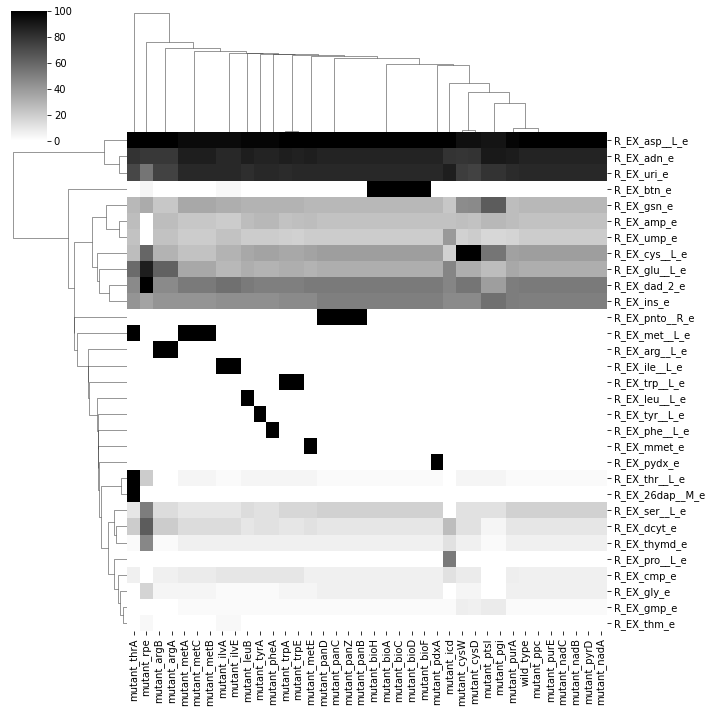

In [41]:
g = sns.clustermap(minimal_medium_all,cmap="binary",vmin=0)

In [42]:
minimal_medium_melted = (minimal_medium_all
                         .reset_index()
                         .melt(id_vars="index",
                               var_name="member",
                                 value_name="sols")
                                 .rename(columns={"index":"exchange_reaction"}))


# Find solutions that are higher than WT
minimal_medium_wt = minimal_medium_melted.query("member == 'wild_type'")
merged1 = minimal_medium_melted.merge(minimal_medium_wt, on="exchange_reaction", suffixes=("", "_wt"))
merged1 = merged1.query("sols > sols_wt")


# Find the mutant-reaction combinations that point to a larger need than normal
max_sols = merged1[["exchange_reaction","sols"]].groupby("exchange_reaction").max()
merged2 = merged1.merge(max_sols, on="exchange_reaction", suffixes=("", "_max"))
merged2 = (
    merged2
    #.query("sols == sols_max") # Find only member-met combinations that stand out
    .query("sols > 50") # If the compound is not used in more than 1/2 of solutions, it's not essential
    )
merged2["met"] = merged2["exchange_reaction"].str.replace(
    r"^R_EX_(.+)_e$",
    r"M_\1_c",
    regex=True
)
merged2.met.unique()

array(['M_trp__L_c', 'M_adn_c', 'M_uri_c', 'M_dad_2_c', 'M_ins_c',
       'M_cys__L_c', 'M_glu__L_c', 'M_gsn_c', 'M_ser__L_c', 'M_dcyt_c',
       'M_thr__L_c', 'M_pnto__R_c', 'M_phe__L_c', 'M_pydx_c',
       'M_leu__L_c', 'M_btn_c', 'M_arg__L_c', 'M_tyr__L_c', 'M_pro__L_c',
       'M_met__L_c', 'M_26dap__M_c', 'M_mmet_c', 'M_ile__L_c'],
      dtype=object)

**Check if compound is in biomass function**

In [137]:
biomass_mets = model_ecoli.reactions.R_BIOMASS_Ec_iML1515_core_75p37M.get_substrates()
biomass_dict = {"M_pydx_c": "M_pydx5p_c",
                "M_pnto__R_c": "M_coa_c"}
biomass_met_translate = lambda x: biomass_dict[x] if x in biomass_dict.keys() else x

merged3 = merged2.copy()
merged3.met = merged3.met.map(biomass_met_translate)

merged3 = merged3[merged3.met.isin(biomass_mets)].copy()
stoichiometry = model_ecoli.reactions.R_BIOMASS_Ec_iML1515_core_75p37M.stoichiometry
merged3.loc[:,"met_biomass_stoich"] = merged3.met.map(lambda x:-stoichiometry[x])

In [138]:
mutant_met_biomass = merged3[["member","met","met_biomass_stoich"]].copy()

def mol2mass(row):
    formula = model_ecoli.metabolites[row.met].metadata["FORMULA"]
    mm = molmass.Formula(formula).mass
    return row.met_biomass_stoich*mm/10

mutant_met_biomass["met_biomass_weight"] = mutant_met_biomass.dropna().apply(mol2mass,axis=1)
mutant_met_biomass.head()

,member,met,met_biomass_stoich,met_biomass_weight
0,mutant_trpA,M_trp__L_c,0.056843,1.160880
1,mutant_trpE,M_trp__L_c,0.056843,1.160880
21,mutant_ptsI,M_cys__L_c,0.091580,1.109566
22,mutant_rpe,M_cys__L_c,0.091580,1.109566
23,mutant_cysW,M_cys__L_c,0.091580,1.109566


In [139]:
relative_abundance = prepare_models_guillen2021.load_relative_abundance_data()
relative_abundance.index = (relative_abundance.index
                            .map(lambda x: "mutant_"+x)
                            .set_names(["member"])
                            )

relative_abundance = (
    relative_abundance
    .reset_index()
    .melt(id_vars="member",
          value_name="relative_abundance",
          var_name="exp_replica")
)


INFO     | Loading relative abundance data...


**Find overlap between datasets and add type of mutants**

In [140]:
RA_biomass_df = relative_abundance.merge(mutant_met_biomass,on="member",how="outer")


RA_biomass_df = RA_biomass_df.merge(mutant_types_df,on="member")
RA_biomass_df

,member,exp_replica,relative_abundance,met,met_biomass_stoich,met_biomass_weight,pathway,type
0,mutant_icd,0,0.23980,M_pro__L_c,0.221055,2.545021,carbon metabolism,carbon metabolism
1,mutant_icd,1,0.29344,M_pro__L_c,0.221055,2.545021,carbon metabolism,carbon metabolism
2,mutant_icd,2,0.45483,M_pro__L_c,0.221055,2.545021,carbon metabolism,carbon metabolism
3,mutant_icd,3,0.24613,M_pro__L_c,0.221055,2.545021,carbon metabolism,carbon metabolism
4,mutant_icd,4,0.23059,M_pro__L_c,0.221055,2.545021,carbon metabolism,carbon metabolism
...,...,...,...,...,...,...,...,...
199,mutant_pyrD,1,0.00000,NaN,NaN,NaN,pyrimidine biosynthesis,nucleotide biosynthesis
200,mutant_pyrD,2,0.00000,NaN,NaN,NaN,pyrimidine biosynthesis,nucleotide biosynthesis
201,mutant_pyrD,3,0.00000,NaN,NaN,NaN,pyrimidine biosynthesis,nucleotide biosynthesis
202,mutant_pyrD,4,0.00000,NaN,NaN,NaN,pyrimidine biosynthesis,nucleotide biosynthesis


Text(0.5, 0, 'w% of biomass function (model)')

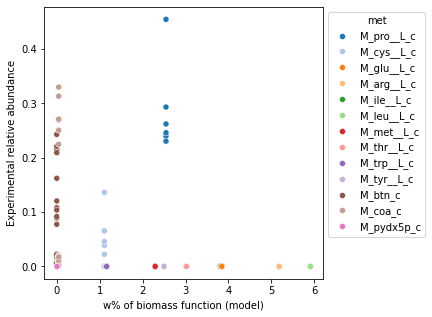

In [141]:
fig,ax = plt.subplots(1,1,figsize=(5,5))

sns.scatterplot(RA_biomass_df,x="met_biomass_weight",y="relative_abundance",hue="met",palette="tab20",ax=ax)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0)
                )

ax.set_ylabel("Experimental relative abundance")
ax.set_xlabel("w% of biomass function (model)")

Text(0.5, 0, 'w% of biomass function (model)')

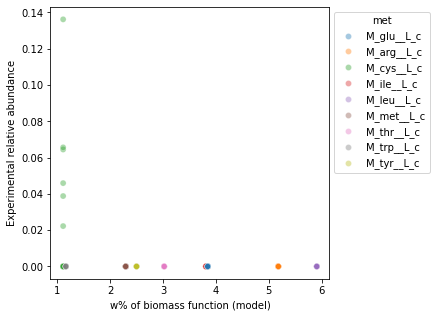

In [143]:
fig,ax = plt.subplots(1,1,figsize=(5,5))

sns.scatterplot(RA_biomass_df.query("type == 'amino acid biosynthesis'"),x="met_biomass_weight",y="relative_abundance",hue="met",ax=ax,alpha=0.4)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0)
                )

ax.set_ylabel("Experimental relative abundance")
ax.set_xlabel("w% of biomass function (model)")

In [144]:
RA_biomass_df.query("relative_abundance>0.2 and met_biomass_weight>2")[["member","exp_replica","met","type","relative_abundance","met_biomass_weight"]]

,member,exp_replica,met,type,relative_abundance,met_biomass_weight
0,mutant_icd,0,M_pro__L_c,carbon metabolism,0.23980,2.545021
1,mutant_icd,1,M_pro__L_c,carbon metabolism,0.29344,2.545021
2,mutant_icd,2,M_pro__L_c,carbon metabolism,0.45483,2.545021
3,mutant_icd,3,M_pro__L_c,carbon metabolism,0.24613,2.545021
4,mutant_icd,4,M_pro__L_c,carbon metabolism,0.23059,2.545021
5,mutant_icd,5,M_pro__L_c,carbon metabolism,0.26230,2.545021


In [145]:
RA_biomass_df.query("met_biomass_weight<1").groupby(["member","met"],as_index=False).first()

,member,met,exp_replica,relative_abundance,met_biomass_stoich,met_biomass_weight,pathway,type
0,mutant_bioA,M_btn_c,0,0.008002,0.000002,0.000049,biotin biosynthesis,vitamins and co-factors
1,mutant_bioC,M_btn_c,0,0.023016,0.000002,0.000049,biotin biosynthesis,vitamins and co-factors
2,mutant_bioD,M_btn_c,0,0.006250,0.000002,0.000049,biotin biosynthesis,vitamins and co-factors
3,mutant_bioF,M_btn_c,0,0.120500,0.000002,0.000049,biotin biosynthesis,vitamins and co-factors
4,mutant_bioH,M_btn_c,0,0.215420,0.000002,0.000049,biotin biosynthesis,vitamins and co-factors
5,mutant_panB,M_coa_c,0,0.009965,0.000576,0.043978,panthothenate biosynthesis,vitamins and co-factors
6,mutant_panC,M_coa_c,0,0.000816,0.000576,0.043978,panthothenate biosynthesis,vitamins and co-factors
7,mutant_panD,M_coa_c,0,0.020705,0.000576,0.043978,panthothenate biosynthesis,vitamins and co-factors
8,mutant_panZ,M_coa_c,0,0.313460,0.000576,0.043978,panthothenate biosynthesis,vitamins and co-factors
9,mutant_pdxA,M_pydx5p_c,0,0.000000,0.000223,0.005466,vitamin B6 biosynthesis,vitamins and co-factors


Text(0.5, 0, 'w% of biomass function (model)')

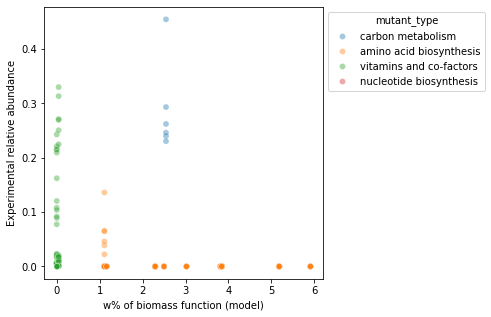

In [ ]:
fig,ax = plt.subplots(1,1,figsize=(5,5))

sns.scatterplot(RA_biomass_df.rename(columns={"type":"mutant_type"}),x="met_biomass_weight",y="relative_abundance",hue="mutant_type",ax=ax,alpha=0.4)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0),
                )
ax.set_ylabel("Experimental relative abundance")
ax.set_xlabel("w% of biomass function (model)")

Text(0.5, 0, 'w% of biomass function (model)')

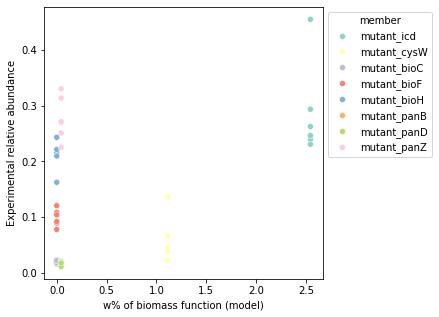

In [146]:
fig,ax = plt.subplots(1,1,figsize=(5,5))

sns.scatterplot(RA_biomass_df.query("relative_abundance > 0.01"),x="met_biomass_weight",y="relative_abundance",hue="member",ax=ax,palette="Set3")
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0),
                )
ax.set_ylabel("Experimental relative abundance")
ax.set_xlabel("w% of biomass function (model)")

In [147]:
len(RA_biomass_df.member.unique())

30

# Top 38 members

### Check if mutants still grow in M9 medium

In [ ]:
still_growing = []
for name,model in models_ecoli.items():
    grows,info =  general.test_growth_model(model, "R_BIOMASS_Ec_iML1515_core_75p37M",env=env_m9)
    if grows:
        print(f"Model {name} is growing: {info}")
        still_growing.append(name)

Set parameter Username


INFO     | Set parameter Username


Academic license - for non-commercial use only - expires 2027-06-05


INFO     | Academic license - for non-commercial use only - expires 2027-06-05


Model mutant_pyrD is growing: mutant_pyrD: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5314271628484023 

Model mutant_ptsI is growing: mutant_ptsI: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5103855425265603 

Model mutant_nadA is growing: mutant_nadA: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5314271628483966 

Model mutant_nadB is growing: mutant_nadB: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5314271628483966 

Model mutant_rpe is growing: mutant_rpe: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5314271628483996 

Model mutant_nadC is growing: mutant_nadC: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5314271628483966 

Model mutant_ppc is growing: mutant_ppc: R_BIOMASS_Ec_iML1515_core_75p37M = 0.5092310328218208 

Model mutant_pgi is growing: mutant_pgi: R_BIOMASS_Ec_iML1515_core_75p37M = 0.517058538389345 



In [ ]:
len(still_growing)

8

##### All models

In [ ]:
comm_ecoli = reframed.Community(models=models_ecoli.values(),
                                community_id="ecoli_mutants")
env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True, warning=False)
biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")


growth = np.ones(len(biomass_rxns))*0.0001
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))
sol = reframed.FBA(comm_ecoli.merged_model,
                constraints=constraints_growth_ecoli
                )
    

    #sol.values["community_growth"]

In [ ]:
sol

Objective: None
Status: Infeasible or Unbounded

##### 7 models + 1

In [ ]:
models = [model for mutant,model in models_ecoli.items() if mutant in top7_mutants]

sols_optimal = {}
for mutant,model in models_ecoli.items():
    if mutant in top7_mutants:
        continue

    comm_ecoli = reframed.Community(models=models+[model],
                                    community_id="ecoli_mutants")
    env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True, warning=False)
    biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")


    growth = np.ones(len(biomass_rxns))*0.01
    growth_upper = np.ones(len(biomass_rxns))*1000
    constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))
    sol = reframed.FBA(comm_ecoli.merged_model,
                    constraints=constraints_growth_ecoli
                    )
    
    if reframed.solvers.solution.Status.OPTIMAL!=sol.status:
    
        print(mutant)
        print(sol)

    else:
        sols_optimal[mutant]=sol.fobj

mutant_pdxA
Objective: None
Status: Infeasible or Unbounded

mutant_metE
Objective: None
Status: Infeasible or Unbounded

mutant_aroC
Objective: None
Status: Infeasible or Unbounded



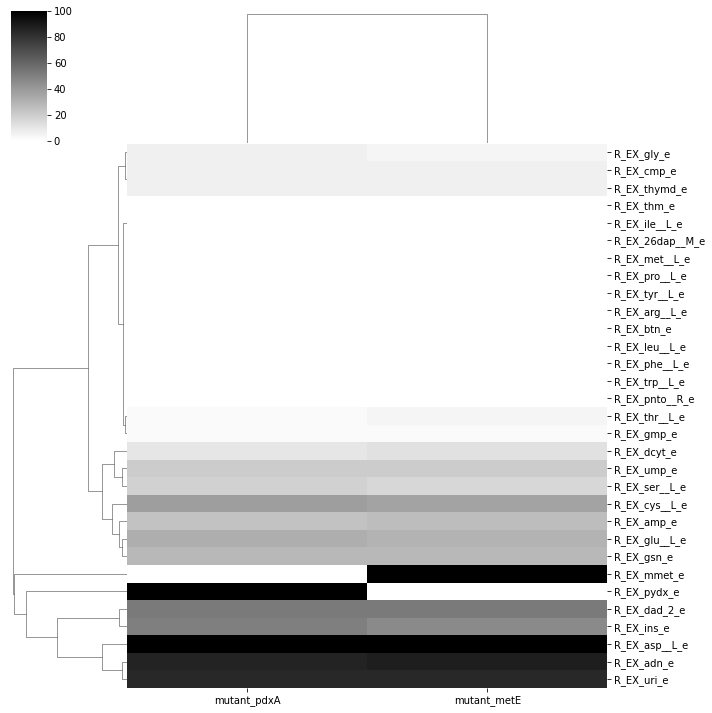

In [ ]:
g = sns.clustermap(minimal_medium_all[["mutant_pdxA","mutant_metE"]],cmap="binary",vmin=0)

In [ ]:
model_copy = models_ecoli["mutant_aroC"].copy()
env_lb.apply(model_copy,inplace=True,exclusive=True)
reframed.FBA(model_copy)

/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_cro4_e
  warn(f'Exchange reaction not in model: {r_id}')
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_fol_e
  warn(f'Exchange reaction not in model: {r_id}')
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_ribflv_e
  warn(f'Exchange reaction not in model: {r_id}')


Objective: -0.0
Status: Optimal

In [ ]:
env_complete = reframed.Environment.complete(model_copy)
env_complete.apply(model_copy,inplace=True,exclusive=True)

reframed.FBA(model_copy)

Objective: -0.0
Status: Optimal

**mutant_pdxA**

In [ ]:
model_copy = models_ecoli["mutant_pdxA"].copy()

In [ ]:
env_complete.apply(model_ecoli,inplace=True,exclusive=True)

reframed.FBA(model_ecoli,objective={"R_EX_pydx_e":1})

Objective: -0.0
Status: Optimal

R_PYDXtpp goes only in one direction

In [ ]:
for rxn in model_ecoli.get_metabolite_reactions("M_pydx_p"):
    print(model_ecoli.reactions[rxn])

R_PYDXtex: M_pydx_e <-> M_pydx_p
R_PYDXtpp: M_pydx_p --> M_pydx_c


In [ ]:
for rxn in model_ecoli.get_metabolite_reactions("M_pydxn_p"):
    print(model_ecoli.reactions[rxn])

NameError: name 'model_ecoli' is not defined

In [ ]:
reframed.FBA(model_ecoli,objective={"R_EX_pydxn_e":1})

Objective: -0.0
Status: Optimal

*pydxn works as a pydx subsitute*

In [ ]:
new_env = reframed.Environment.from_compounds(list(m9_compounds)+["pydxn"])
new_env.apply(model_copy,inplace=True,exclusive=True)
reframed.FBA(model_copy)

Objective: 0.5314336463024606
Status: Optimal